In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import math
import scrapbook as sb
#import papermill as pm
from datetime import datetime, timedelta
# from tqdm import tqdm

from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap

In [105]:
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "./data/data.db"

In [106]:
## Pull Data ##

def pull_tx_data(ticker, start_date, end_date, db_path):
    """Load one ticker's cleaned OHLC data for a date range, plus the prior trading day.

    The extra row before start_date provides the previous close needed to compute
    the first return in the report period.

    Args:
        ticker: Stock ticker, e.g. "AAPL".
        start_date: Report start date as a "YYYY-MM-DD" string.
        end_date: Report end date as a "YYYY-MM-DD" string (inclusive).
        db_path: Path to the SQLite database containing the ohlc_hw_cleaned table.

    Returns:
        DataFrame sorted by ts with columns ts, open, high, low, close, adj_close, volume, ticker.
    """
    ## Load Data ##
    conn = sqlite3.connect(db_path)
    df = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned WHERE ticker = ?",
                           conn, params=(ticker,))
    conn.close()
    df = df.sort_values('ts')
    df = df[df['ts'] <= end_date]
    
    start_date_inclusive = df[df['ts']< start_date]['ts'].iloc[-1]
    df= df[df['ts'] >= start_date_inclusive]
    df = df[['ts', 'open', 'high', 'low', 'close', 'adj_close', 'volume', 'ticker']]
    return(df)

In [107]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))

In [108]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""
    return returns.rolling(window).std() * np.sqrt(252)

In [109]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    # Hint:
    cum_max = prices.expanding().max()
    Drawdown = (prices - cum_max) / cum_max
    return (Drawdown)

In [110]:
# This is quite a friendly rfr
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    mean_return = returns.mean()
    std_return = returns.std()
    if std_return is None or np.size(std_return) == 0 or np.all(pd.isna(std_return)):
        return float('nan')
    else:
        return (mean_return * 252 - risk_free_rate) / (std_return * (252)**.5)

In [111]:
## Price and Moving Average Plot ##
def plot_price_ma(df, ticker, ax=None, ma_window=50, vol_window=20):
    """Plot adjusted close colored by rolling volatility, with a moving average.

    Each price segment is red when rolling volatility is above its mean over the report,
    green when at or below it, and gray during the volatility warm-up (no estimate yet).
    The coloring is retrospective, since the mean uses the whole report period.

    Args:
        df: Price data with ts and adj_close columns, sorted by date.
        ticker: Ticker used in the title.
        ax: Matplotlib axes to draw on; a new figure is created if None.
        ma_window: Moving-average window in trading days.
        vol_window: Rolling-volatility window in trading days.

    Returns:
        The matplotlib axes with the plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ## Prices, Moving Average, Rolling Volatility ##
    dates = mdates.date2num(pd.to_datetime(df['ts']))
    price = df['adj_close'].to_numpy()
    ma = df['adj_close'].rolling(ma_window).mean()
    returns = df['adj_close'] / df['adj_close'].shift(1) - 1
    vol = returns.rolling(vol_window).std().to_numpy()
    threshold = np.nanmean(vol)

    ## Color Each Segment by Volatility (gray = warm-up, no estimate yet) ##
    seg_vol = vol[1:]
    colors = np.where(np.isnan(seg_vol), 'gray', np.where(seg_vol > threshold, 'red', 'green'))
    points = np.column_stack([dates, price])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    ax.add_collection(LineCollection(segments, colors=colors, linewidth=2))

    ## Moving Average ##
    ax.plot(dates, ma, color='black', linewidth=1.5, linestyle='--')

    ## Formatting ##
    ax.autoscale_view()
    ax.xaxis_date()
    ax.set_title(f"{ticker} Price and {ma_window}-day MA")
    ax.set_ylabel('Adjusted Close')
    ax.grid(alpha=0.3)
    ax.legend(handles=[Line2D([], [], color='red', lw=2, label='High vol (> mean)'),
                       Line2D([], [], color='green', lw=2, label='Low vol (<= mean)'),
                       Line2D([], [], color='gray', lw=2, label='Vol warm-up (n/a)'),
                       Line2D([], [], color='black', lw=1.5, ls='--', label=f'{ma_window}-day MA')],
              loc='best', fontsize=8)
    return ax

In [112]:
def plot_daily_returns(df, ticker, ax=None):
    """Plot daily simple returns as a bar chart, green for gains and red for losses.

    The first row (the prior trading day from pull_tx_data) has no return and is dropped,
    so the bars cover only the report period.

    Args:
        df: Price data with ts and adj_close columns, sorted by date.
        ticker: Ticker used in the title.
        ax: Matplotlib axes to draw on; a new figure is created if None.

    Returns:
        The matplotlib axes with the plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ## Daily Returns (first row is the prior day, so it has no return) ##
    returns = (df['adj_close'] / df['adj_close'].shift(1) - 1).iloc[1:]
    dates = pd.to_datetime(df['ts']).iloc[1:]
    colors = np.where(returns >= 0, 'green', 'red')

    ## Bars and Zero Line ##
    ax.bar(dates, returns, color=colors, width=1)
    ax.axhline(0, color='black', linewidth=1)

    ## Formatting ##
    ax.set_title(f"{ticker} Daily Returns")
    ax.set_ylabel('Daily Return')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis='y', alpha=0.3)
    return ax

In [113]:
## Drawdown Plot ##

def plot_drawdown(df, ticker, ax=None):
    """Plot per-date drawdown from the running peak as a red gradient area and mark the maximum drawdown.

    Drawdown = adj_close / running peak - 1, computed over the report period only
    (the prior-day row from pull_tx_data is dropped).

    Args:
        df: Price data with ts and adj_close columns, sorted by date.
        ticker: Ticker used in the title.
        ax: Matplotlib axes to draw on; a new figure is created if None.

    Returns:
        The matplotlib axes with the plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ## Drawdown from Running Peak (report period only, prior-day row dropped) ##
    prices = df['adj_close'].iloc[1:].reset_index(drop=True)
    dates = mdates.date2num(pd.to_datetime(df['ts'].iloc[1:]))
    drawdown = (prices / prices.cummax() - 1).to_numpy()
    ymin = min(drawdown.min() * 1.15, -0.01)

    ## Red/Pink Gradient Fill (darker = deeper drawdown) ##
    fill = ax.fill_between(dates, drawdown, 0, color='none')
    cmap = LinearSegmentedColormap.from_list('drawdown', ['#b71c1c', '#ffcdd2'])
    gradient = ax.imshow(np.linspace(0, 1, 256).reshape(-1, 1), cmap=cmap, aspect='auto',
                         origin='lower', extent=[dates[0], dates[-1], ymin, 0])
    gradient.set_clip_path(fill.get_paths()[0], transform=ax.transData)
    ax.plot(dates, drawdown, color='#b71c1c', linewidth=1)

    ## Maximum Drawdown Point ##
    i = drawdown.argmin()
    ax.scatter(dates[i], drawdown[i], color='black', s=40, zorder=5)
    ax.annotate(f"Max DD {drawdown[i]:.1%}\n{mdates.num2date(dates[i]):%Y-%m-%d}",
                (dates[i], drawdown[i]), xytext=(8, 8), textcoords='offset points', fontsize=8)

    ## Formatting ##
    ax.set_xlim(dates[0], dates[-1])
    ax.set_ylim(ymin, 0)
    ax.xaxis_date()
    ax.set_title(f"{ticker} Maximum Drawdown")
    ax.set_ylabel('Drawdown')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.3)
    return ax

In [114]:
def plot_rolling_volatility(df, ticker, ax=None, vol_window=20):
    """Plot rolling daily volatility with its mean, shading high-vol (red) and low-vol (green) regions.

    Volatility is the rolling standard deviation of daily simple returns (not annualized).
    The warm-up period before vol_window returns exist is left blank, not filled.

    Args:
        df: Price data with ts and adj_close columns, sorted by date.
        ticker: Ticker used in the title.
        ax: Matplotlib axes to draw on; a new figure is created if None.
        vol_window: Rolling-volatility window in trading days.

    Returns:
        The matplotlib axes with the plot.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))

    ## Rolling Volatility and Mean ##
    returns = df['adj_close'] / df['adj_close'].shift(1) - 1
    vol = returns.rolling(vol_window).std()
    mean_vol = vol.mean()
    dates = pd.to_datetime(df['ts'])

    ## Line, Mean Line, High/Low Shading ##
    ax.plot(dates, vol, color='black', linewidth=1.5, label=f'{vol_window}-day volatility')
    ax.axhline(mean_vol, color='gray', linestyle='--', linewidth=1, label=f'Mean ({mean_vol:.2%})')
    ax.fill_between(dates, vol, mean_vol, where=vol > mean_vol, color='red', alpha=0.3,
                    interpolate=True, label='High vol (> mean)')
    ax.fill_between(dates, vol, mean_vol, where=vol < mean_vol, color='green', alpha=0.3,
                    interpolate=True, label='Low vol (< mean)')

    ## Formatting ##
    ax.set_title(f"{ticker} Rolling Volatility ({vol_window}-day)")
    ax.set_ylabel('Daily Volatility')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.3)
    ax.legend(loc='best', fontsize=8)
    return ax




In [115]:
def create_stock_grid(df, ticker, start_date, end_date):
    """Build the 2x2 report figure: price/MA, daily returns, drawdown, and rolling volatility.

    Args:
        df: Price data with ts and adj_close columns, sorted by date.
        ticker: Ticker used in the titles.
        start_date: Report start date, shown in the figure title.
        end_date: Report end date, shown in the figure title.

    Returns:
        (fig, axes): the matplotlib figure and its 2x2 array of axes.
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    plot_price_ma(df, ticker, ax=axes[0, 0])     # top left
    plot_daily_returns(df, ticker, ax=axes[0, 1])        # top right
    plot_drawdown(df, ticker, ax=axes[1, 0])      # bottom left
    plot_rolling_volatility(df, ticker, ax=axes[1, 1])       # bottom right
    fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=14)
    fig.tight_layout()
    return fig, axes

In [116]:
def create_summary_table(df_tx):
    """Compute the report's summary metrics, print them as a table, and return them.

    Expects df_tx to already have returns (daily log returns), sharpe_ratio, and
    max_drawdown columns. Annualization assumes 252 trading days per year.

    Args:
        df_tx: Price data with adj_close, returns, sharpe_ratio, and max_drawdown columns.

    Returns:
        DataFrame with Metric and Value (formatted string) columns.
    """
    tr = df_tx['adj_close'].iloc[-1] / df_tx['adj_close'].iloc[0] - 1
    n = len(df_tx['returns'].dropna())
    ar = math.e**(sum(df_tx['returns'].dropna()) * 252 / n) - 1
    av = df_tx['returns'].std() * (252)**.5
    sr = df_tx['sharpe_ratio'].iloc[-1]
    md = df_tx['max_drawdown'].min()
    bd = df_tx['returns'].max()
    wd = df_tx['returns'].min()
    posd = df_tx[df_tx['returns'] > 0]['returns'].count() / df_tx['returns'].dropna().count()
    aud = df_tx[df_tx['returns'] > 0]['returns'].mean()
    add = df_tx[df_tx['returns'] < 0]['returns'].mean()
    
    ## Build and Print Table ##
    summary = pd.DataFrame({
        'Metric': ['Total Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio',
                   'Maximum Drawdown', 'Best Day', 'Worst Day', 'Pct Positive Days',
                   'Average Up Day', 'Average Down Day'],
        'Value': [f"{tr:.2%}", f"{ar:.2%}", f"{av:.2%}", f"{sr:.2f}",
                  f"{md:.2%}", f"{bd:.2%}", f"{wd:.2%}", f"{posd:.2%}",
                  f"{aud:.2%}", f"{add:.2%}"]})

    print(f"{'Metric':<24}  {'Value':<8}\n{'-' * 24}  {'-' * 8}")
    for metric, value in zip(summary['Metric'], summary['Value']):
        print(f"{metric:<24}  {value:<8}")
    return summary

In [117]:
def validate_data(df, ticker, start_date, end_date, min_returns=20, n_rows=5):
    """Validate the inputs and pulled data, print a summary, and show the first and last rows.

    Prints "{ticker} from {start} to {end}: {N} trading days" and the actual first/last
    observation dates. n returns need n + 1 prices, so at least min_returns + 1 rows are required.

    Args:
        df: Data returned by pull_tx_data.
        ticker: Ticker being analyzed.
        start_date: Report start date as a "YYYY-MM-DD" string.
        end_date: Report end date as a "YYYY-MM-DD" string.
        min_returns: Minimum number of returns the report needs.
        n_rows: Number of rows to show from the start and end of the data.

    Raises:
        ValueError: If start_date is after end_date, no data was found, or history is insufficient.
    """
    ## Validate Inputs ##
    if start_date > end_date:
        raise ValueError(f"start_date ({start_date}) is after end_date ({end_date})")
    if df.empty:
        raise ValueError(f"No data found for {ticker} between {start_date} and {end_date}")

    ## Summary ##
    in_range = df[(df['ts'] >= start_date) & (df['ts'] <= end_date)]
    print(f"{ticker} from {start_date} to {end_date}: {len(in_range)} trading days")
    print(f"Actual first observation: {df['ts'].iloc[0]} | Actual last observation: {df['ts'].iloc[-1]}")

    ## First and Last Rows ##
    display(df.head(n_rows))
    display(df.tail(n_rows))

    ## Check History ##
    if len(df) < min_returns + 1:
        raise ValueError(f"Insufficient history for {ticker}: {len(df)} prices give {max(len(df) - 1, 0)} returns, "
                         f"but {min_returns} returns require at least {min_returns + 1} prices")

In [118]:

df_tx = pull_tx_data(ticker, start_date, end_date, db_path)
validate_data(df_tx, ticker, start_date, end_date)
len(df_tx['ts'])
df_tx['returns'] = calculate_returns(df_tx['adj_close'])
df_tx['volatility'] = calculate_volatility(df_tx['adj_close'])
df_tx['max_drawdown'] = calculate_max_drawdown(df_tx['adj_close'])
df_tx['sharpe_ratio'] = calculate_sharpe_ratio(df_tx['returns'].dropna())


AAPL from 2024-01-01 to 2024-12-31: 202 trading days
Actual first observation: 2023-12-29 00:00:00 | Actual last observation: 2024-10-18 00:00:00


,ts,open,high,low,close,adj_close,volume,ticker
10843,2023-12-29 00:00:00,193.90,194.40,191.73,192.53,191.80,42672148,AAPL
10844,2024-01-02 00:00:00,187.15,188.44,183.89,185.64,184.94,82488674,AAPL
10845,2024-01-03 00:00:00,184.22,185.88,183.43,184.25,183.55,58414460,AAPL
10846,2024-01-04 00:00:00,182.15,183.09,180.88,181.91,181.22,71983570,AAPL
10847,2024-01-05 00:00:00,181.99,182.76,180.17,181.18,180.50,62379661,AAPL


,ts,open,high,low,close,adj_close,volume,ticker
11041,2024-10-14 00:00:00,228.70,231.73,228.60,231.30,231.30,39882100,AAPL
11042,2024-10-15 00:00:00,233.61,237.49,232.37,233.85,233.85,64751400,AAPL
11043,2024-10-16 00:00:00,231.60,232.12,229.84,231.78,231.78,34082240,AAPL
11044,2024-10-17 00:00:00,233.43,233.85,230.52,232.15,232.15,32993810,AAPL
11045,2024-10-18 00:00:00,236.18,236.18,234.01,235.00,235.00,45441281,AAPL


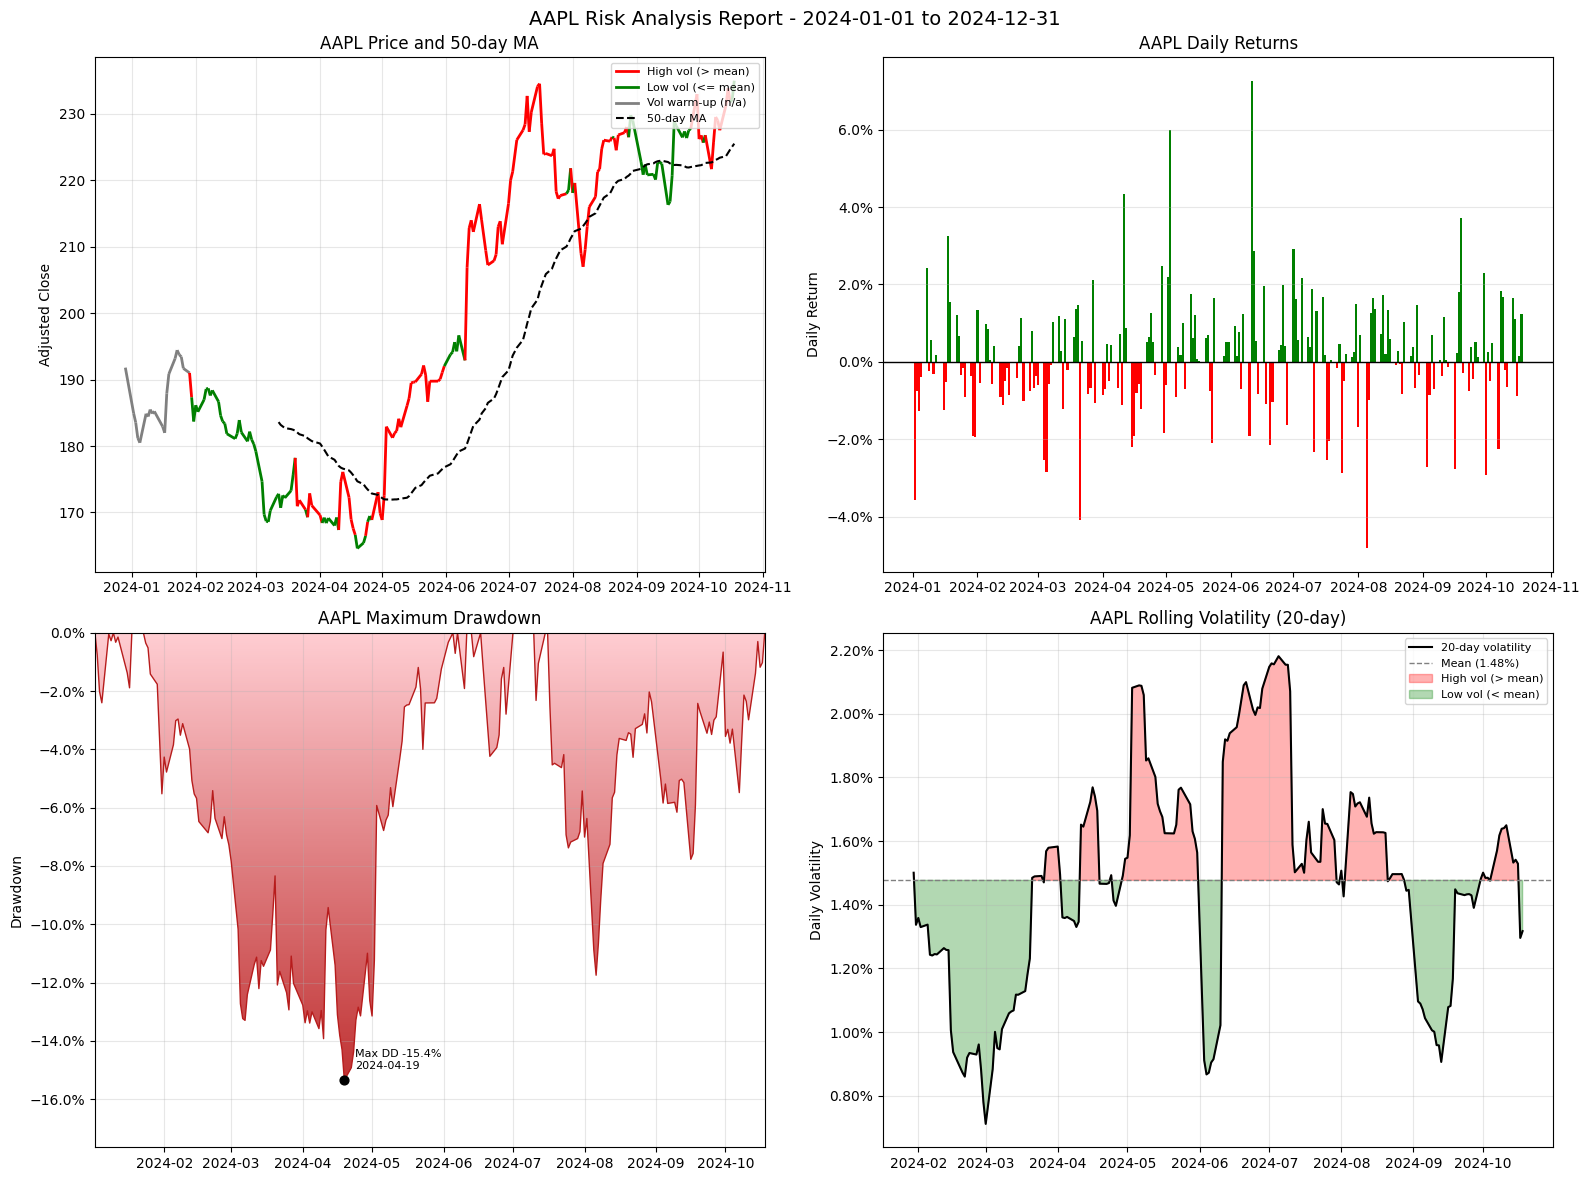

In [119]:
fig, ax = create_stock_grid(df_tx, ticker, start_date, end_date)

In [120]:
tx_summary_table = create_summary_table(df_tx)
scrap_book_summary_table = pd.DataFrame([{
    'ticker': ticker,
    'avg_daily_return': df_tx['returns'].mean(),  # Mean daily log return over period (fraction)
    'avg_volatility': df_tx['volatility'].mean(),     # Mean of rolling volatility
    'max_drawdown': df_tx['max_drawdown'].min(),       # Worst drawdown over entire period
    'sharpe_ratio': df_tx['sharpe_ratio'].iloc[-1],       # Annualized Sharpe ratio
    'total_return': (df_tx['adj_close'].iloc[-1] / df_tx['adj_close'].iloc[0] - 1)
}])


Metric                    Value   
------------------------  --------
Total Return              22.52%  
Annualized Return         28.84%  
Annualized Volatility     23.92%  
Sharpe Ratio              0.98    
Maximum Drawdown          -15.35% 
Best Day                  7.01%   
Worst Day                 -4.94%  
Pct Positive Days         55.45%  
Average Up Day            1.08%   
Average Down Day          -1.12%  


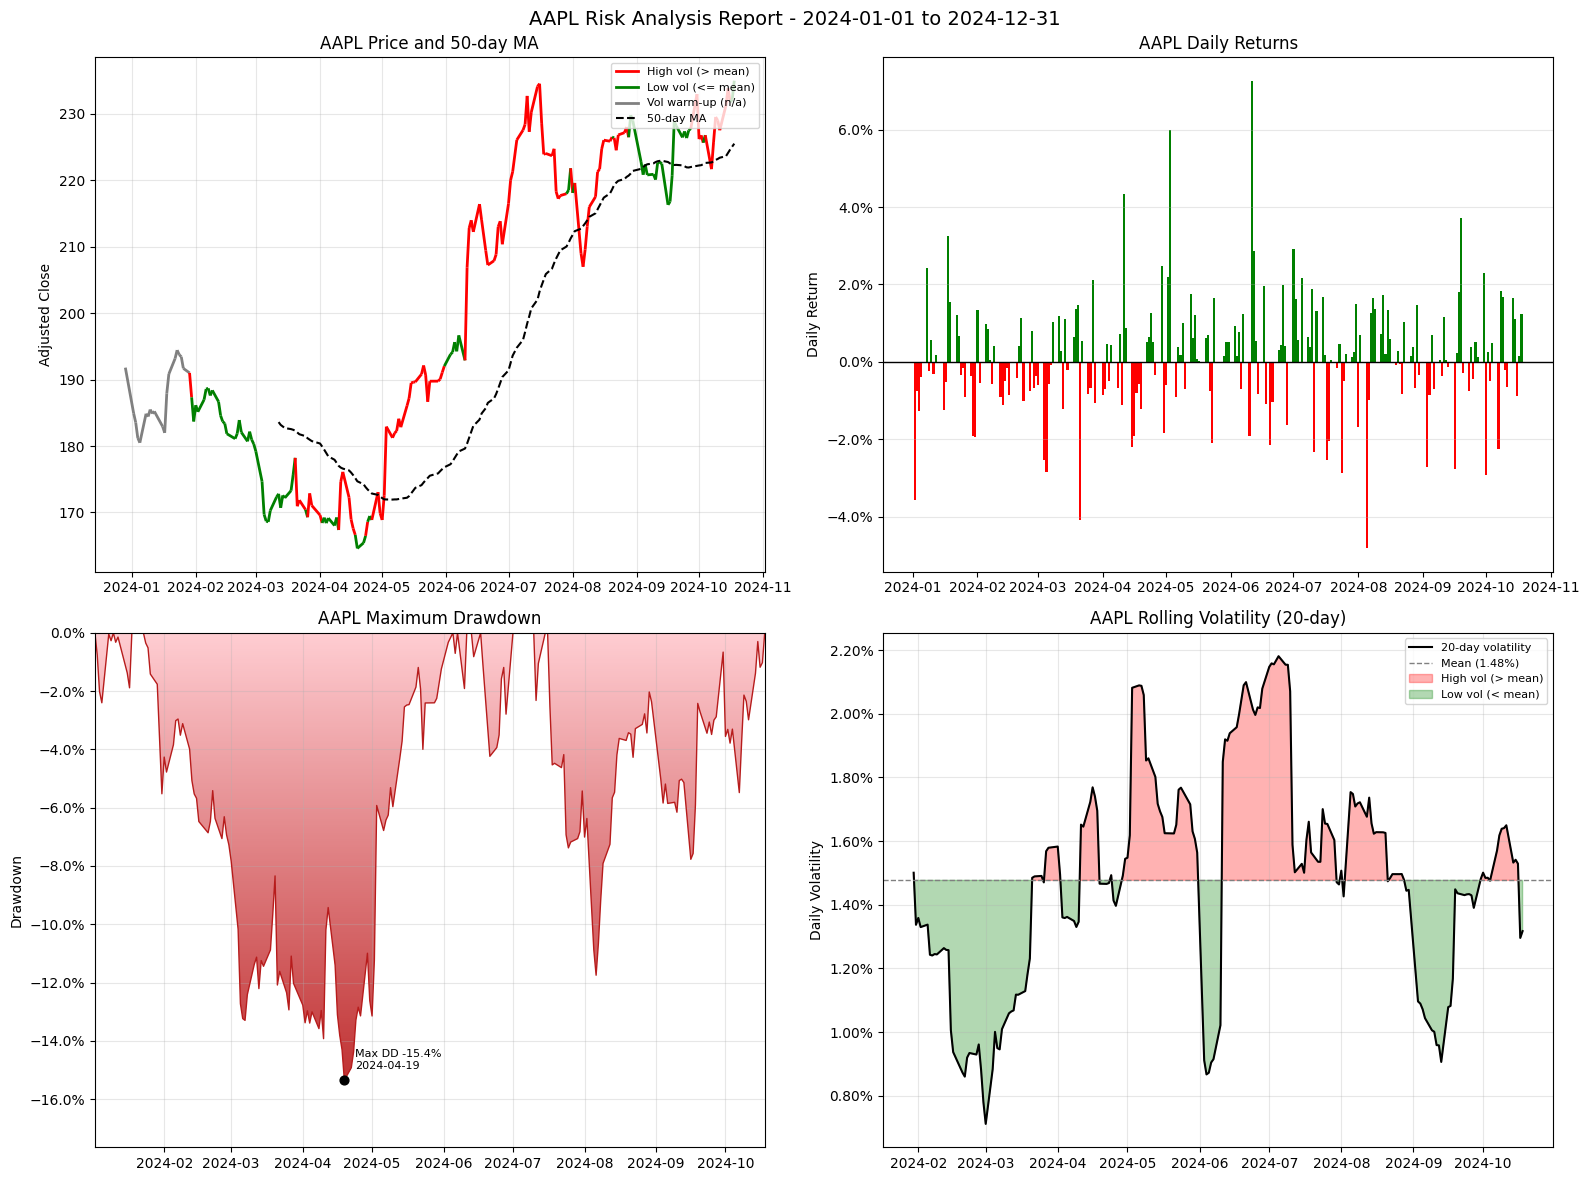

In [121]:
sb.glue("summary_table", tx_summary_table, encoder="pandas")
sb.glue("scrap_book_summary_table", scrap_book_summary_table, encoder="pandas")
sb.glue("report_figure", fig, encoder="display")